# Fraud Risk Intelligence & Decision Engine

## Project Objective

Develop a production-oriented fraud risk intelligence pipeline
that generates calibrated fraud probabilities, cost-sensitive
operational decisions, and explainable predictions.

## 1. Data Forensics & Quality Engineering

Perform a comprehensive data audit to identify missing values,
duplicates, invalid observations, extreme values, and potential
data leakage before model development.

In [81]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import fisher_exact
from sklearn.model_selection import train_test_split
from IPython.display import display

# Reproducibility
RANDOM_STATE = 42

# Project paths
PROJECT_ROOT = Path.cwd()

DATA_PATH = (
    PROJECT_ROOT / "data" / "raw"
    / "transaction_fraud_risk_advanced_dataset.csv"
)

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Display configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

sns.set_theme(style="whitegrid")

print("Project initialized successfully.")

Project initialized successfully.


In [82]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Number of transactions:", len(df))
print("Number of columns:", df.shape[1])

display(df.head())

Dataset shape: (3000, 25)
Number of transactions: 3000
Number of columns: 25


,transaction_id,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,device_age_days,merchant_risk_score,ip_risk_score,email_age_days,login_to_transaction_minutes,card_presence,channel,country,device_type,merchant_category,authentication_level,new_device,billing_address_mismatch,customer_tier,fraud
0,TXN5000001,20,0,35.0100,47.9300,6,12,783,0,0,221,0.6210,0.1070,2975,3.1200,Not present,E-commerce,Sri Lanka,iOS,Grocery,Standard,0,1,Basic,1
1,TXN5000002,4,1,29.6600,78.0200,2,6,564,0,0,799,0.5530,0.0420,2104,22.5600,Not present,POS,UK,macOS,Grocery,Strong,0,1,Basic,0
2,TXN5000003,0,4,46.0500,21.3900,5,10,1618,0,0,879,0.4060,0.1230,2194,18.6800,Present,E-commerce,Sri Lanka,Android,Grocery,Standard,0,0,Gold,0
3,TXN5000004,15,4,77.0200,95.2900,4,10,1433,1,0,877,0.3840,0.6000,3925,13.4200,Present,E-commerce,Sri Lanka,Other,Grocery,Strong,0,0,Basic,0
4,TXN5000005,8,3,187.6500,6.0800,1,10,50,0,0,826,0.5880,0.3270,2047,19.9000,Not present,POS,Sri Lanka,Android,Grocery,Standard,0,0,Basic,0


In [83]:
TARGET = "fraud"
ID_COLUMN = "transaction_id"

categorical_features = [
    "card_presence",
    "channel",
    "country",
    "device_type",
    "merchant_category",
    "authentication_level",
    "customer_tier",
]

binary_features = [
    "new_device",
    "billing_address_mismatch",
]

numerical_features = [
    "hour",
    "day_of_week",
    "transaction_amount",
    "distance_from_usual_location_km",
    "transactions_last_1h",
    "transactions_last_24h",
    "account_age_days",
    "failed_logins_24h",
    "prior_chargebacks",
    "device_age_days",
    "merchant_risk_score",
    "ip_risk_score",
    "email_age_days",
    "login_to_transaction_minutes",
]

feature_columns = (
    numerical_features
    + categorical_features
    + binary_features
)

assert set(df.columns) == set(
    feature_columns + [TARGET, ID_COLUMN]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))
print("Total potential predictors:", len(feature_columns))

Numerical features: 14
Categorical features: 7
Binary features: 2
Total potential predictors: 23


In [84]:
assert df[TARGET].notna().all()
assert set(df[TARGET].unique()) == {0, 1}

development_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df[TARGET],
    random_state=RANDOM_STATE
)

development_df = development_df.copy()
test_df = test_df.copy()

assert set(development_df[ID_COLUMN]).isdisjoint(
    test_df[ID_COLUMN]
)

print("Development dataset:", development_df.shape)
print("Reserved test dataset:", test_df.shape)

# Use only development data for analytical investigations
audit_df = development_df.copy()

Development dataset: (2400, 25)
Reserved test dataset: (600, 25)


In [85]:

import numpy as np
import pandas as pd
from scipy.stats import fisher_exact


def create_schema_report(df):
    """Generate a column-level data quality report."""

    report = pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "non_null_count": df.notna().sum(),
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100,
        "unique_count": df.nunique(),
        "cardinality_percentage": (
            df.nunique() / len(df) * 100
        )
    })

    report.index.name = "feature"

    return report


def analyze_missingness(df, target):
    """Investigate associations between missingness and fraud."""

    results = []

    for column in df.columns:

        if column == target or not df[column].isna().any():
            continue

        missing = df[column].isna()

        contingency = pd.crosstab(
            missing, df[target]
        ).reindex(
            index=[False, True],
            columns=[0, 1],
            fill_value=0
        )

        _, p_value = fisher_exact(contingency)

        results.append({
            "feature": column,
            "missing_count": missing.sum(),
            "missing_percentage": missing.mean() * 100,
            "fraud_rate_missing": (
                df.loc[missing, target].mean()
            ),
            "fraud_rate_present": (
                df.loc[~missing, target].mean()
            ),
            "fisher_p_value": p_value
        })

    return pd.DataFrame(results)


def detect_iqr_outliers(df, columns):
    """Identify extreme observations without removing them."""

    results = []

    for column in columns:

        values = df[column].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        # IQR can be misleading for zero-inflated variables
        if iqr == 0:
            count = np.nan
        else:
            count = (
                (values < lower) | (values > upper)
            ).sum()

        results.append({
            "feature": column,
            "minimum": values.min(),
            "maximum": values.max(),
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": count,
            "outlier_percentage": count / len(values) * 100,
            "iqr_applicable": iqr > 0
        })

    return pd.DataFrame(results)


### 1.1 Schema and Data Quality Assessment

Investigate data types, missing values, unique values,
and feature cardinality to identify potential data quality issues.

In [86]:
import importlib
import src.data_quality as dq

importlib.reload(dq)

print(dir(dq))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'analyze_missingness', 'create_schema_report', 'detect_iqr_outliers', 'fisher_exact', 'np', 'pd']


In [87]:
from src.data_quality import (
    create_schema_report,
    analyze_missingness,
    detect_iqr_outliers
)

audit_df.info()

schema_report = create_schema_report(audit_df)

display(schema_report)

schema_report.to_csv(
    METRICS_DIR / "data_quality_schema.csv"
)

print("Total missing values:",
      audit_df.isna().sum().sum())

print("Rows containing missing values:",
      audit_df.isna().any(axis=1).sum())

<class 'pandas.DataFrame'>
Index: 2400 entries, 1894 to 2380
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   transaction_id                   2400 non-null   str    
 1   hour                             2400 non-null   int64  
 2   day_of_week                      2400 non-null   int64  
 3   transaction_amount               2360 non-null   float64
 4   distance_from_usual_location_km  2344 non-null   float64
 5   transactions_last_1h             2400 non-null   int64  
 6   transactions_last_24h            2400 non-null   int64  
 7   account_age_days                 2400 non-null   int64  
 8   failed_logins_24h                2400 non-null   int64  
 9   prior_chargebacks                2400 non-null   int64  
 10  device_age_days                  2400 non-null   int64  
 11  merchant_risk_score              2350 non-null   float64
 12  ip_risk_score                    

,data_type,non_null_count,missing_count,missing_percentage,unique_count,cardinality_percentage
feature,,,,,,
transaction_id,str,2400,0,0.0000,2400,100.0000
hour,int64,2400,0,0.0000,24,1.0000
day_of_week,int64,2400,0,0.0000,7,0.2917
transaction_amount,float64,2360,40,1.6667,2258,94.0833
distance_from_usual_location_km,float64,2344,56,2.3333,2001,83.3750
transactions_last_1h,int64,2400,0,0.0000,11,0.4583
transactions_last_24h,int64,2400,0,0.0000,24,1.0000
account_age_days,int64,2400,0,0.0000,1328,55.3333
failed_logins_24h,int64,2400,0,0.0000,4,0.1667


Total missing values: 455
Rows containing missing values: 425


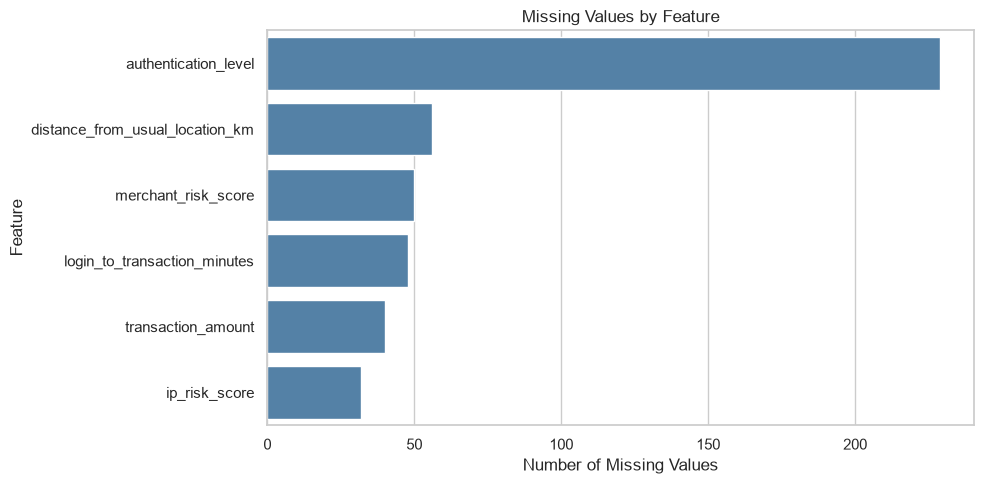

In [88]:
missing_counts = audit_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]
missing_counts = missing_counts.sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_counts.values,
    y=missing_counts.index,
    color="steelblue"
)

plt.title("Missing Values by Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "data_quality_missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [89]:
duplicate_report = {
    "exact_duplicate_rows": int(
        df.duplicated().sum()
    ),
    "duplicate_transaction_ids": int(
        df[ID_COLUMN].duplicated().sum()
    ),
    "duplicate_predictor_rows": int(
        df[feature_columns].duplicated().sum()
    ),
    "missing_transaction_ids": int(
        df[ID_COLUMN].isna().sum()
    )
}

display(pd.Series(duplicate_report))

pd.Series(duplicate_report).to_csv(
    METRICS_DIR / "duplicate_report.csv",
    header=["count"]
)

assert duplicate_report["duplicate_transaction_ids"] == 0
assert duplicate_report["duplicate_predictor_rows"] == 0

exact_duplicate_rows         0
duplicate_transaction_ids    0
duplicate_predictor_rows     0
missing_transaction_ids      0
dtype: int64

In [90]:
missingness_report = analyze_missingness(
    audit_df,
    TARGET
)

missingness_report = missingness_report.sort_values(
    "fisher_p_value"
)

display(missingness_report)

missingness_report.to_csv(
    METRICS_DIR / "missingness_analysis.csv",
    index=False
)

,feature,missing_count,missing_percentage,fraud_rate_missing,fraud_rate_present,fisher_p_value
5,authentication_level,229,9.5417,0.2096,0.1119,0.0001
2,merchant_risk_score,50,2.0833,0.0200,0.1234,0.0254
1,distance_from_usual_location_km,56,2.3333,0.0714,0.1224,0.3045
0,transaction_amount,40,1.6667,0.0750,0.1220,0.4703
3,ip_risk_score,32,1.3333,0.0938,0.1216,0.7902
4,login_to_transaction_minutes,48,2.0000,0.1042,0.1216,1.0000


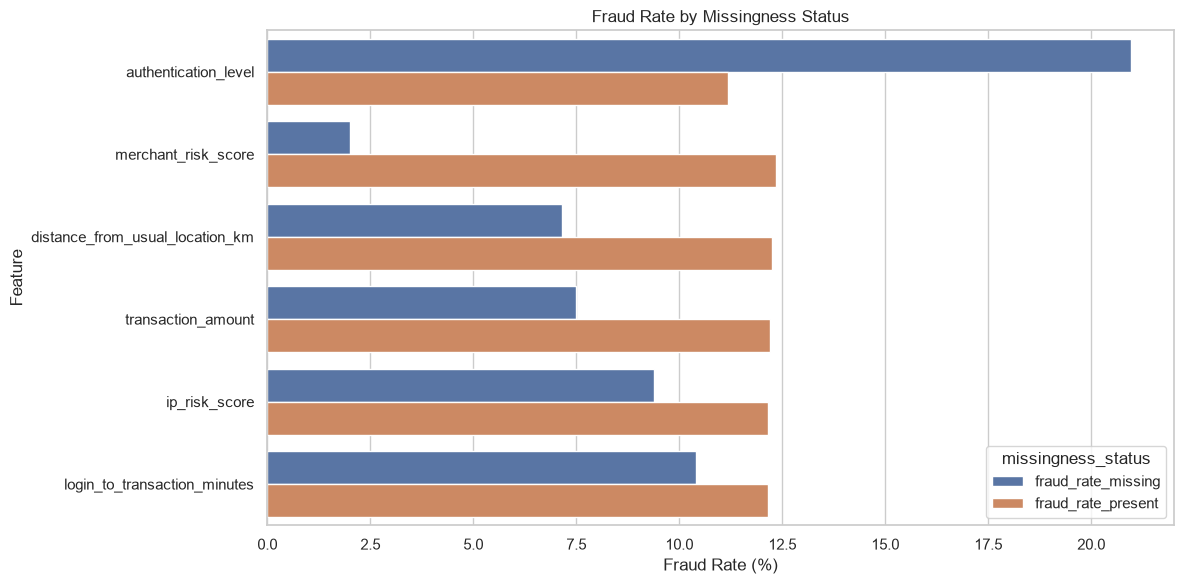

In [91]:
plot_data = missingness_report.melt(
    id_vars="feature",
    value_vars=[
        "fraud_rate_missing",
        "fraud_rate_present"
    ],
    var_name="missingness_status",
    value_name="fraud_rate"
)

plot_data["fraud_rate"] *= 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    y="feature",
    x="fraud_rate",
    hue="missingness_status"
)

plt.title("Fraud Rate by Missingness Status")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "missingness_fraud_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [92]:
non_negative_columns = [
    "distance_from_usual_location_km",
    "transactions_last_1h",
    "transactions_last_24h",
    "account_age_days",
    "failed_logins_24h",
    "prior_chargebacks",
    "device_age_days",
    "email_age_days",
    "login_to_transaction_minutes"
]

integer_columns = [
    "hour",
    "day_of_week",
    "transactions_last_1h",
    "transactions_last_24h",
    "account_age_days",
    "failed_logins_24h",
    "prior_chargebacks",
    "device_age_days",
    "email_age_days"
]

invalid_checks = {
    "invalid_hour": (
        ~audit_df["hour"].between(0, 23)
    ).sum(),

    "invalid_day_of_week": (
        ~audit_df["day_of_week"].between(0, 6)
    ).sum(),

    "non_positive_transaction_amount": (
        audit_df["transaction_amount"] <= 0
    ).sum(),

    "invalid_merchant_risk": (
        audit_df["merchant_risk_score"].notna()
        & ~audit_df["merchant_risk_score"].between(0, 1)
    ).sum(),

    "invalid_ip_risk": (
        audit_df["ip_risk_score"].notna()
        & ~audit_df["ip_risk_score"].between(0, 1)
    ).sum(),

    "invalid_new_device": (
        ~audit_df["new_device"].isin([0, 1])
    ).sum(),

    "invalid_billing_address_mismatch": (
        ~audit_df["billing_address_mismatch"].isin([0, 1])
    ).sum(),

    "inconsistent_transaction_velocity": (
        audit_df["transactions_last_1h"]
        > audit_df["transactions_last_24h"]
    ).sum(),

    "invalid_target": (
        ~audit_df[TARGET].isin([0, 1])
    ).sum(),

    "infinite_values": (
        audit_df.select_dtypes(include="number")
        .isin([np.inf, -np.inf])
        .sum()
        .sum()
    )
}

for column in non_negative_columns:
    invalid_checks[f"negative_{column}"] = (
        audit_df[column] < 0
    ).sum()

for column in integer_columns:
    values = audit_df[column].dropna()

    invalid_checks[f"non_integer_{column}"] = (
        values % 1 != 0
    ).sum()

invalid_report = pd.DataFrame(
    invalid_checks.items(),
    columns=["validation_rule", "invalid_count"]
)

display(invalid_report)

invalid_report.to_csv(
    METRICS_DIR / "invalid_values_report.csv",
    index=False
)

,validation_rule,invalid_count
0,invalid_hour,0
1,invalid_day_of_week,0
2,non_positive_transaction_amount,0
3,invalid_merchant_risk,0
4,invalid_ip_risk,0
5,invalid_new_device,0
6,invalid_billing_address_mismatch,0
7,inconsistent_transaction_velocity,0
8,invalid_target,0
9,infinite_values,0


In [93]:
consistency_report = {
    "device_older_than_account": (
        audit_df["device_age_days"]
        > audit_df["account_age_days"]
    ).sum(),

    "new_device_with_age_above_30_days": (
        (audit_df["new_device"] == 1)
        & (audit_df["device_age_days"] > 30)
    ).sum()
}

display(pd.Series(consistency_report))

device_older_than_account            992
new_device_with_age_above_30_days    391
dtype: int64

In [94]:
numerical_summary = audit_df[
    numerical_features + binary_features
].describe().T

numerical_summary["skewness"] = audit_df[
    numerical_features + binary_features
].skew()

numerical_summary["median"] = audit_df[
    numerical_features + binary_features
].median()

display(numerical_summary)

numerical_summary.to_csv(
    METRICS_DIR / "numerical_summary.csv"
)

,count,mean,std,min,25%,50%,75%,max,skewness,median
hour,2400.0000,11.6708,6.9207,0.0000,6.0000,12.0000,18.0000,23.0000,-0.0414,12.0000
day_of_week,2400.0000,2.9442,1.9660,0.0000,1.0000,3.0000,5.0000,6.0000,0.0578,3.0000
transaction_amount,2360.0000,134.3472,249.2323,4.1200,49.6025,90.3200,156.3325,5538.1516,15.9679,90.3200
distance_from_usual_location_km,2344.0000,37.5151,50.5099,0.4900,16.8650,30.1250,48.3675,1173.2691,14.8463,30.1250
transactions_last_1h,2400.0000,2.1842,1.4556,0.0000,1.0000,2.0000,3.0000,10.0000,0.6990,2.0000
transactions_last_24h,2400.0000,7.8229,5.1222,0.0000,6.0000,8.0000,9.0000,113.0000,13.2938,8.0000
account_age_days,2400.0000,884.6638,519.7073,1.0000,436.5000,888.5000,1331.0000,1799.0000,0.0221,888.5000
failed_logins_24h,2400.0000,0.3308,0.5729,0.0000,0.0000,0.0000,1.0000,3.0000,1.6857,0.0000
prior_chargebacks,2400.0000,0.1246,0.3499,0.0000,0.0000,0.0000,0.0000,3.0000,2.7902,0.0000
device_age_days,2400.0000,750.0354,428.6903,2.0000,381.0000,741.0000,1116.2500,1499.0000,0.0158,741.0000


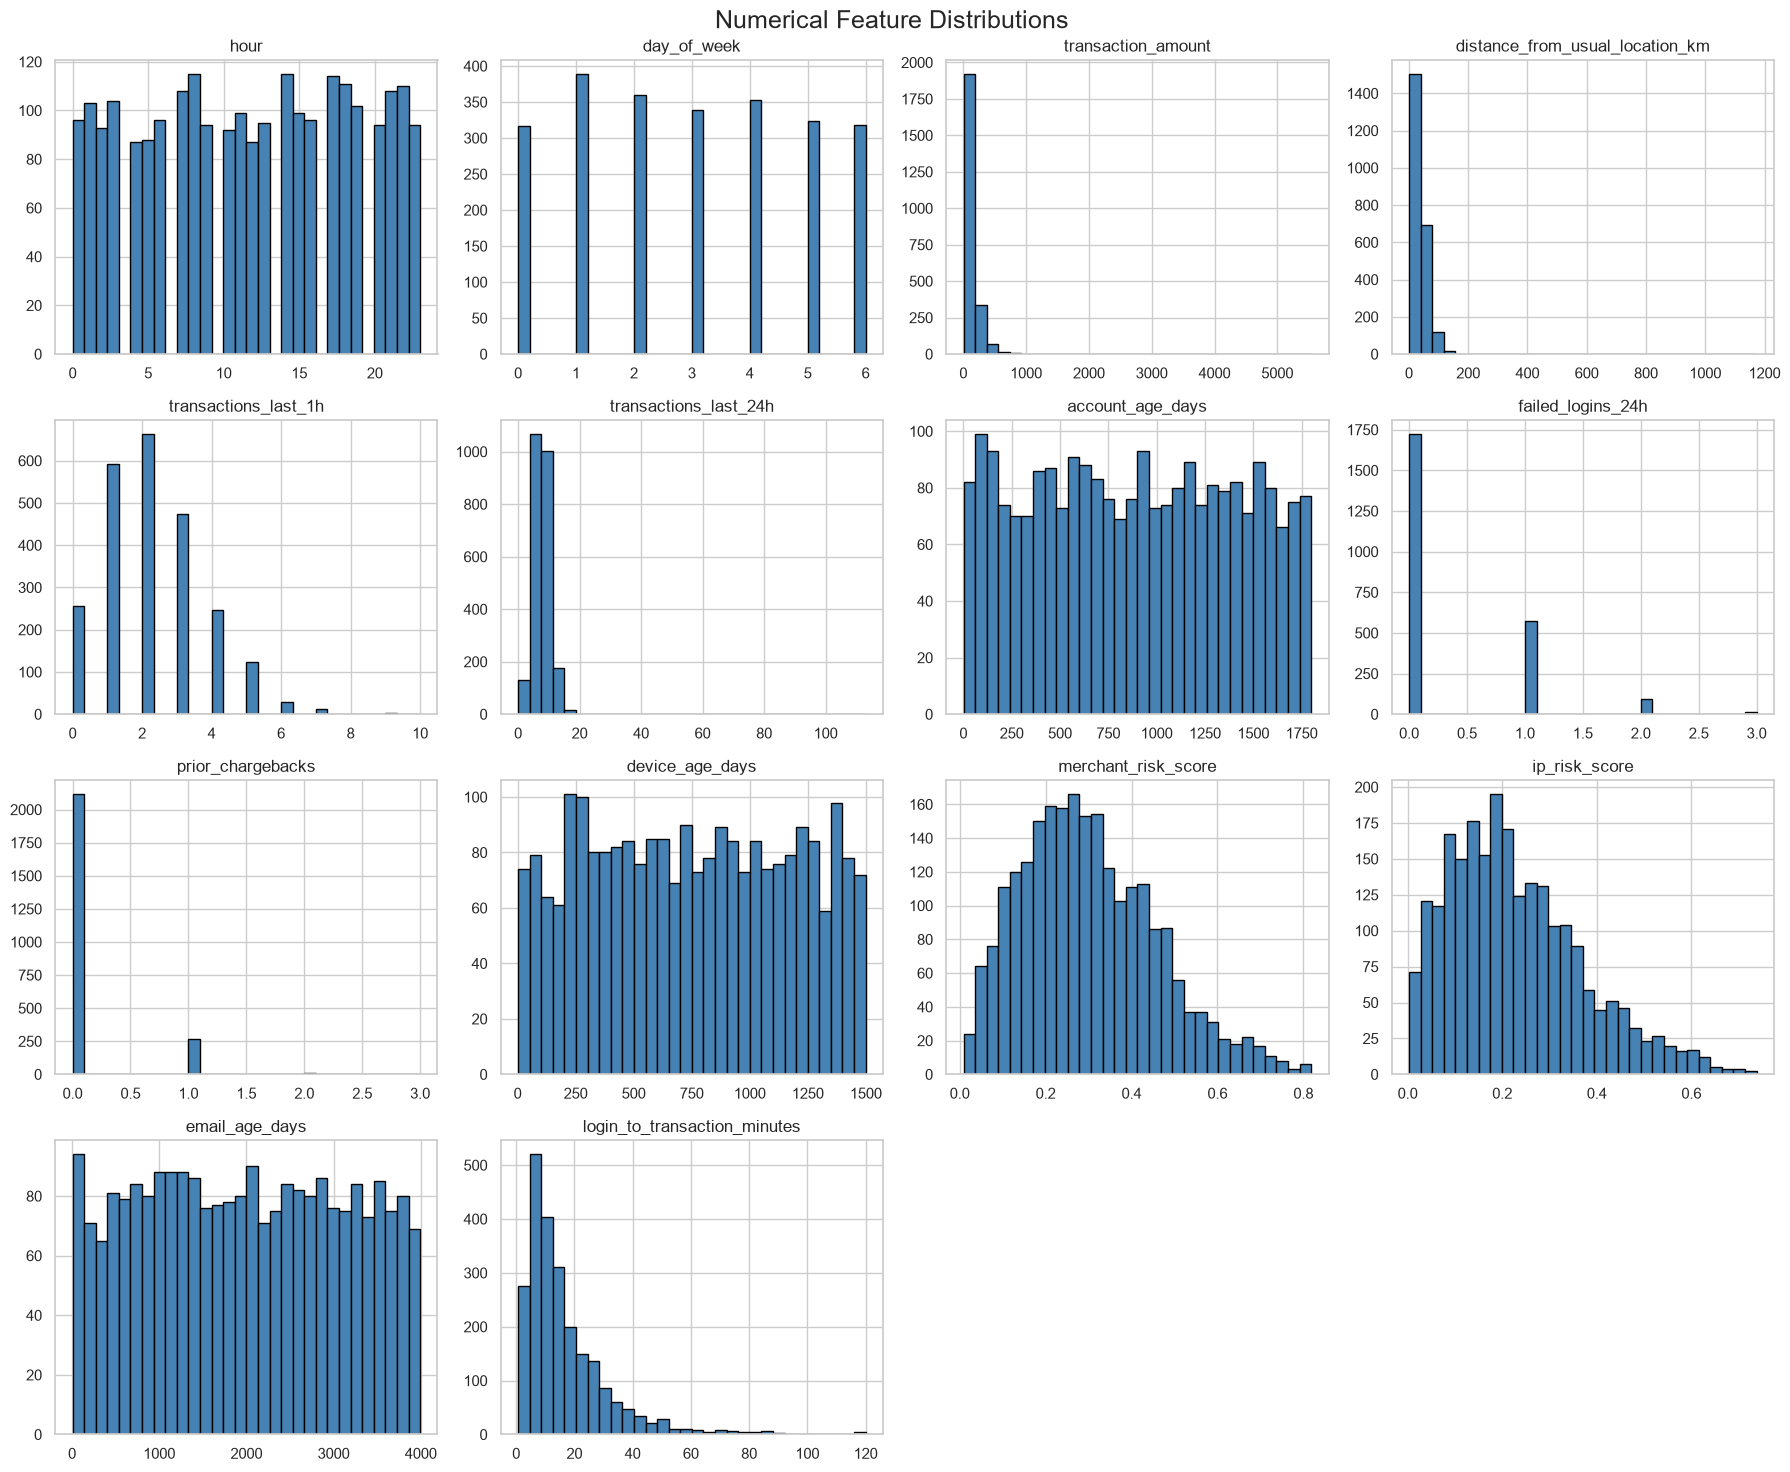

In [95]:
audit_df[numerical_features].hist(
    figsize=(18, 15),
    bins=30,
    color="steelblue",
    edgecolor="black"
)

plt.suptitle(
    "Numerical Feature Distributions",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [96]:
categorical_records = []

for column in categorical_features:

    print(f"\nFeature: {column}")

    counts = audit_df[column].value_counts(
        dropna=False
    )

    display(counts)

    for category, count in counts.items():

        categorical_records.append({
            "feature": column,
            "category": category,
            "count": count,
            "percentage": count / len(audit_df) * 100
        })

categorical_report = pd.DataFrame(
    categorical_records
)

categorical_report.to_csv(
    METRICS_DIR / "categorical_distributions.csv",
    index=False
)


Feature: card_presence


card_presence
Present        1396
Not present    1004
Name: count, dtype: int64


Feature: channel


channel
E-commerce    938
POS           770
Mobile App    471
ATM           221
Name: count, dtype: int64


Feature: country


country
Sri Lanka    1316
UAE           205
India         204
UK            188
Australia     170
Singapore     168
USA           149
Name: count, dtype: int64

... (4 outputs left out)


Feature: authentication_level


authentication_level
Strong      1094
Standard    1077
NaN          229
Name: count, dtype: int64


Feature: customer_tier


customer_tier
Basic       898
Silver      733
Gold        540
Platinum    229
Name: count, dtype: int64

In [97]:
outlier_features = [
    column for column in numerical_features
    if column not in ["hour", "day_of_week"]
]

outlier_report = detect_iqr_outliers(
    audit_df,
    outlier_features
)

display(
    outlier_report.sort_values(
        "outlier_count",
        ascending=False
    )
)

outlier_report.to_csv(
    METRICS_DIR / "outlier_report.csv",
    index=False
)

,feature,minimum,maximum,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percentage,iqr_applicable
0,transaction_amount,4.1200,5538.1516,49.6025,156.3325,106.7300,-110.4925,316.4275,158.0000,6.6949,True
11,login_to_transaction_minutes,0.6600,120.0000,6.9375,21.9850,15.0475,-15.6337,44.5562,127.0000,5.3997,True
1,distance_from_usual_location_km,0.4900,1173.2691,16.8650,48.3675,31.5025,-30.3887,95.6213,72.0000,3.0717,True
3,transactions_last_24h,0.0000,113.0000,6.0000,9.0000,3.0000,1.5000,13.5000,71.0000,2.9583,True
9,ip_risk_score,0.0030,0.7380,0.1190,0.3130,0.1940,-0.1720,0.6040,36.0000,1.5203,True
2,transactions_last_1h,0.0000,10.0000,1.0000,3.0000,2.0000,-2.0000,6.0000,16.0000,0.6667,True
8,merchant_risk_score,0.0090,0.8180,0.1830,0.4050,0.2220,-0.1500,0.7380,16.0000,0.6809,True
5,failed_logins_24h,0.0000,3.0000,0.0000,1.0000,1.0000,-1.5000,2.5000,11.0000,0.4583,True
4,account_age_days,1.0000,1799.0000,436.5000,1331.0000,894.5000,-905.2500,2672.7500,0.0000,0.0000,True
7,device_age_days,2.0000,1499.0000,381.0000,1116.2500,735.2500,-721.8750,2219.1250,0.0000,0.0000,True


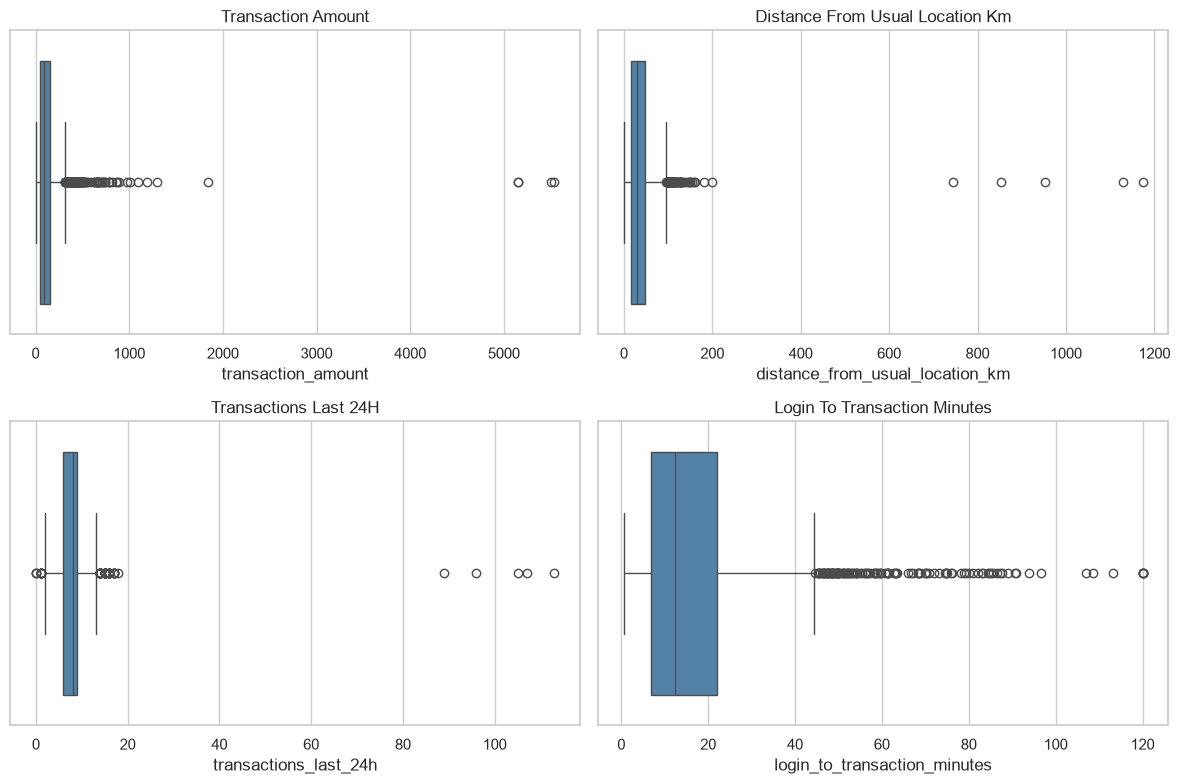

In [98]:
selected_features = [
    "transaction_amount",
    "distance_from_usual_location_km",
    "transactions_last_24h",
    "login_to_transaction_minutes"
]

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8)
)

for column, ax in zip(
    selected_features, axes.flatten()
):

    sns.boxplot(
        x=audit_df[column],
        ax=ax,
        color="steelblue"
    )

    ax.set_title(column.replace("_", " ").title())

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "extreme_observations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Data Leakage Assessment

The transaction ID is excluded from model predictors because
it is an identifier rather than a defensible behavioral feature.

The fraud label is used exclusively as the prediction target.

Historical chargebacks, transaction velocity, authentication,
location baselines, device information and external risk scores
must be calculated using information available before the
operational transaction decision.

The dataset does not provide feature lineage, complete timestamps,
customer identifiers or label maturity dates. Therefore, point-in-time
correctness, customer-level independence and temporal leakage
cannot be fully verified.

Risk-sensitive features are provisionally permitted under explicit
point-in-time availability assumptions. Their influence will be
investigated through feature exclusion sensitivity experiments.

Production deployment requires verification of these assumptions.

## 2. Data Splitting & Validation Strategy

Establish a reproducible validation framework using stratified
data partitioning and cross-validation.

The dataset is divided into four independent, non-overlapping
subsets:

- Training: 50%
- Calibration: 15%
- Threshold validation: 15%
- Final testing: 20%

The final test dataset is reserved exclusively for evaluation
after model selection, calibration and threshold optimization.

In [99]:
from src.validation import (
    split_development_data,
    create_split_summary,
    create_cv_strategy
)

train_df, calibration_df, threshold_df = (
    split_development_data(
        development_df,
        target=TARGET,
        random_state=RANDOM_STATE
    )
)

print("Training dataset:", train_df.shape)
print("Calibration dataset:", calibration_df.shape)
print("Threshold dataset:", threshold_df.shape)
print("Final test dataset:", test_df.shape)

Training dataset: (1500, 25)
Calibration dataset: (450, 25)
Threshold dataset: (450, 25)
Final test dataset: (600, 25)


In [100]:
datasets = {
    "Training": train_df,
    "Calibration": calibration_df,
    "Threshold Validation": threshold_df,
    "Final Test": test_df
}

split_summary = create_split_summary(
    datasets,
    target=TARGET
)

display(split_summary)

split_summary.to_csv(
    METRICS_DIR / "data_split_summary.csv",
    index=False
)

,dataset,total_transactions,legitimate_transactions,fraudulent_transactions,fraud_rate_percentage
0,Training,1500,1318,182,12.1333
1,Calibration,450,395,55,12.2222
2,Threshold Validation,450,396,54,12.0000
3,Final Test,600,527,73,12.1667


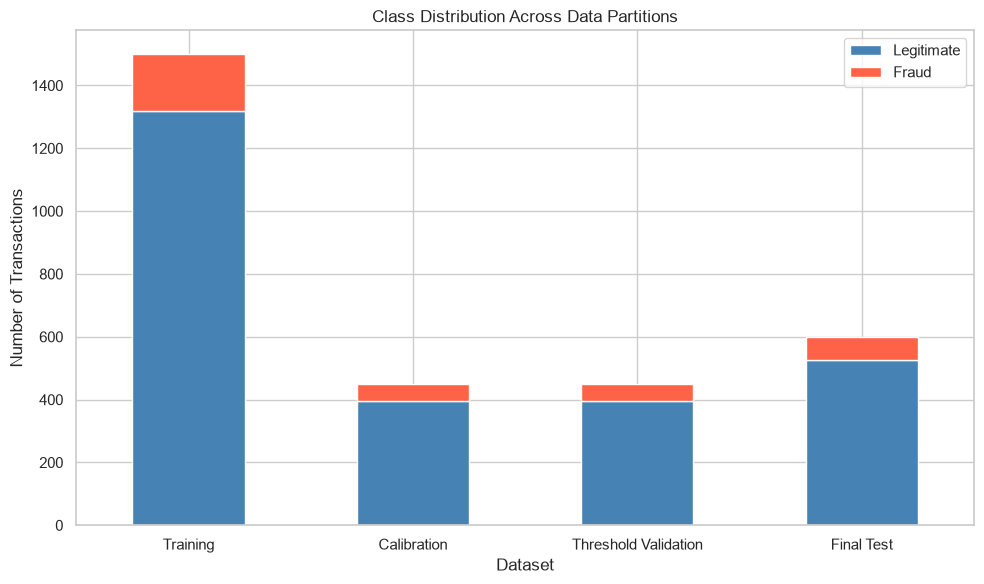

In [101]:
plot_df = split_summary.set_index("dataset")[
    [
        "legitimate_transactions",
        "fraudulent_transactions"
    ]
]

plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["steelblue", "tomato"]
)

plt.title("Class Distribution Across Data Partitions")
plt.xlabel("Dataset")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(["Legitimate", "Fraud"])
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "data_split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [102]:
from itertools import combinations

# Check for overlapping transaction IDs
for (name_a, data_a), (name_b, data_b) in combinations(
    datasets.items(), 2
):

    overlapping_ids = (
        set(data_a[ID_COLUMN])
        & set(data_b[ID_COLUMN])
    )

    assert len(overlapping_ids) == 0, (
        f"Overlap detected: {name_a} and {name_b}"
    )

    print(f"{name_a} vs {name_b}: No overlap")


# Verify all original transactions are preserved
all_ids = set().union(
    *(set(dataset[ID_COLUMN])
      for dataset in datasets.values())
)

assert all_ids == set(df[ID_COLUMN])

assert sum(
    len(dataset) for dataset in datasets.values()
) == len(df)

# Verify both target classes exist in every subset
for name, dataset in datasets.items():

    assert set(dataset[TARGET].unique()) == {0, 1}

print("\nAll data integrity checks passed!")

Training vs Calibration: No overlap
Training vs Threshold Validation: No overlap
Training vs Final Test: No overlap
Calibration vs Threshold Validation: No overlap
Calibration vs Final Test: No overlap
Threshold Validation vs Final Test: No overlap

All data integrity checks passed!


In [103]:
# Training dataset
X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].copy()

# Calibration dataset
X_calibration = calibration_df[feature_columns].copy()
y_calibration = calibration_df[TARGET].copy()

# Threshold validation dataset
X_threshold = threshold_df[feature_columns].copy()
y_threshold = threshold_df[TARGET].copy()

# Final test dataset
X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_calibration:", X_calibration.shape)
print("y_calibration:", y_calibration.shape)

print("X_threshold:", X_threshold.shape)
print("y_threshold:", y_threshold.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1500, 23)
y_train: (1500,)
X_calibration: (450, 23)
y_calibration: (450,)
X_threshold: (450, 23)
y_threshold: (450,)
X_test: (600, 23)
y_test: (600,)


In [104]:
cv = create_cv_strategy(
    random_state=RANDOM_STATE
)

print("Cross-validation strategy:", cv)
print("Number of folds:", cv.get_n_splits())

Cross-validation strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Number of folds: 5


In [105]:
fold_records = []

for fold, (train_index, val_index) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    fold_y_train = y_train.iloc[train_index]
    fold_y_val = y_train.iloc[val_index]

    fold_records.append({
        "fold": fold,
        "training_samples": len(fold_y_train),
        "validation_samples": len(fold_y_val),
        "training_fraud_count": int(
            fold_y_train.sum()
        ),
        "validation_fraud_count": int(
            fold_y_val.sum()
        ),
        "training_fraud_rate": (
            fold_y_train.mean() * 100
        ),
        "validation_fraud_rate": (
            fold_y_val.mean() * 100
        )
    })

cv_summary = pd.DataFrame(fold_records)

display(cv_summary)

cv_summary.to_csv(
    METRICS_DIR / "cross_validation_summary.csv",
    index=False
)

,fold,training_samples,validation_samples,training_fraud_count,validation_fraud_count,training_fraud_rate,validation_fraud_rate
0,1,1200,300,146,36,12.1667,12.0000
1,2,1200,300,146,36,12.1667,12.0000
2,3,1200,300,146,36,12.1667,12.0000
3,4,1200,300,145,37,12.0833,12.3333
4,5,1200,300,145,37,12.0833,12.3333


In [106]:
print("Available time-related features:")

time_features = [
    "hour",
    "day_of_week",
    "login_to_transaction_minutes"
]

display(df[time_features].head())

print("\nFirst transaction ID:")
print(df[ID_COLUMN].iloc[0])

print("\nLast transaction ID:")
print(df[ID_COLUMN].iloc[-1])

print(
    "\nTransaction IDs are sorted:",
    df[ID_COLUMN].is_monotonic_increasing
)

Available time-related features:


,hour,day_of_week,login_to_transaction_minutes
0,20,0,3.1200
1,4,1,22.5600
2,0,4,18.6800
3,15,4,13.4200
4,8,3,19.9000



First transaction ID:
TXN5000001

Last transaction ID:
TXN5003000

Transaction IDs are sorted: True


### Temporal Validation and Leakage Limitations

The dataset does not contain complete transaction timestamps,
customer identifiers or historical feature calculation metadata.

Although transaction identifiers are sequential, their
chronological meaning cannot be verified.

Therefore, chronological splitting and customer-level grouped
validation cannot be reliably implemented with the available data.

Stratified random splitting and five-fold cross-validation are
used as reproducible alternatives.

Production validation should include chronological holdout
datasets, point-in-time feature verification and monitoring
for changes in fraud patterns over time.

In [107]:
split_manifest = pd.concat(
    [
        dataset[[ID_COLUMN]].assign(dataset=name)
        for name, dataset in datasets.items()
    ],
    ignore_index=True
)

split_manifest = split_manifest.sort_values(
    ID_COLUMN
).reset_index(drop=True)

assert len(split_manifest) == len(df)
assert split_manifest[ID_COLUMN].is_unique

split_manifest.to_csv(
    METRICS_DIR / "data_split_manifest.csv",
    index=False
)

print("Split manifest saved successfully.")
print("Total assignments:", len(split_manifest))

Split manifest saved successfully.
Total assignments: 3000


In [108]:
eda_df = train_df.copy()

print("EDA dataset shape:", eda_df.shape)
print("Fraud rate:", eda_df[TARGET].mean() * 100)

EDA dataset shape: (1500, 25)
Fraud rate: 12.133333333333333
